# 03 — Robustness analysis
All 180 perturbed evaluations on MVTec AD. The earlier Bottle pilot is retained in [its historical commit](https://github.com/basharbd/msc-visual-anomaly-detection/blob/05d2c08243bf059698238e6df12a1cb80a918802/notebooks/lighting_and_blur_robustness.ipynb) and [pilot table](../reports/lighting_blur/bottle_seed0_pilot.csv). This notebook analyzes the full paired benchmark using published CSVs.

**RQ2 (Chapter 7).** Test images are paired across original and perturbed conditions. Brightness factors are 0.85 and 0.70; Pillow Gaussian blur radii are 0.75 and 1.50 pixels at the resized input scale. Normal references remain unchanged.

## Full MVTec AD study

Each row compares a perturbed test condition with its own clean one-shot baseline. All 15 categories use the same three fixed reference selections for every condition. The references share test images. The reported spread across categories is descriptive.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
import io

repo = Path.cwd()
if repo.name == "notebooks":
    repo = repo.parent
reports = repo / "reports" / "lighting_blur"
runs = pd.read_csv(reports / "per_run.csv")
conditions = ["brightness_085", "brightness_070", "blur_075", "blur_150"]
endpoints = ["image_auroc", "pixel_aupro", "image_ap", "image_f1max", "pixel_auroc", "pixel_f1max"]
assert len(runs) == 180 and runs.category.nunique() == 15
assert set(runs.condition) == set(conditions) and set(runs.seed) == {0, 1, 2}
assert not runs.duplicated(["category", "seed", "condition"]).any()
assert runs.groupby(["category", "seed"]).condition.nunique().eq(4).all()
deltas = [m + "_change_pp" for m in endpoints]
for metric, delta in zip(endpoints, deltas):
    assert np.allclose(runs[delta], 100 * (runs[metric] - runs[metric + "_original"]), atol=1e-10, rtol=0)
categories = runs.groupby(["category", "condition"])[deltas].mean()
macro = categories.groupby("condition").mean().loc[conditions]
archived = pd.read_csv(reports / "macro_change_pp.csv").set_index("condition")
np.testing.assert_allclose(macro, archived.loc[conditions, deltas], atol=1e-10)
display(macro.round(3))

,image_auroc_change_pp,pixel_aupro_change_pp,image_ap_change_pp,image_f1max_change_pp,pixel_auroc_change_pp,pixel_f1max_change_pp
condition,,,,,,
brightness_085,0.105,0.005,0.084,0.082,0.007,0.038
brightness_070,-0.058,-0.124,-0.027,-0.075,-0.026,-0.063
blur_075,-0.659,-0.482,-0.412,-0.484,-0.178,-0.648
blur_150,-3.077,-1.528,-1.980,-2.274,-0.787,-2.149


### Category-level sensitivity

Color shows the signed change in percentage points after averaging the three reference selections within category. Both panels use the same scale.

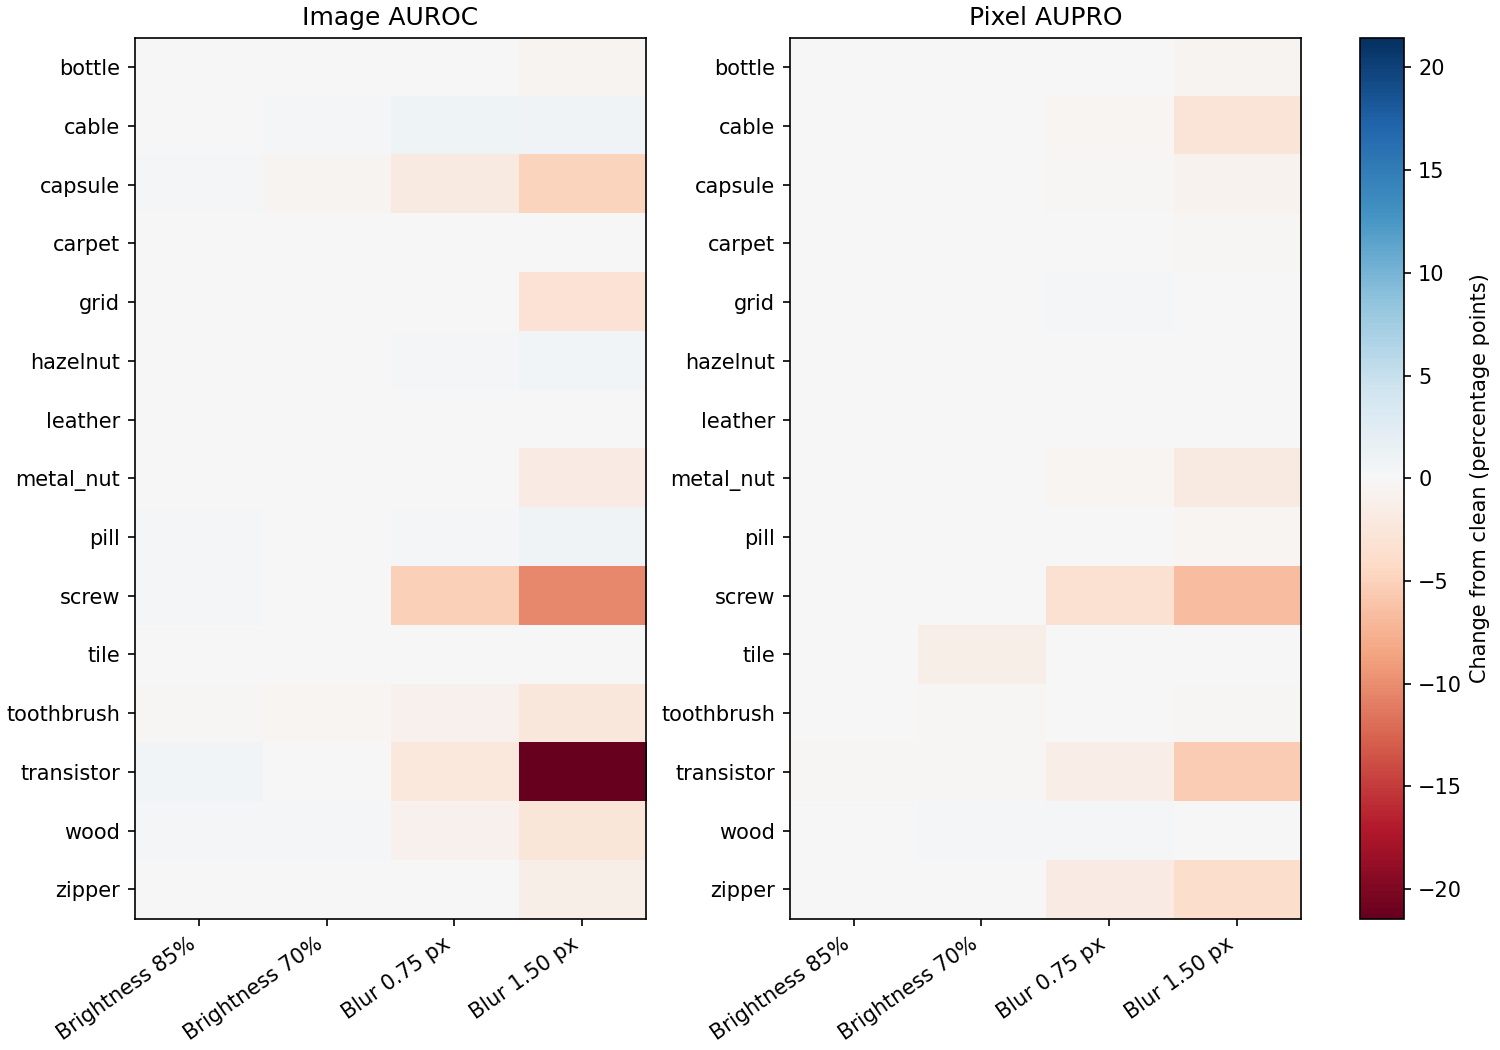

In [2]:
labels = ["Brightness 85%", "Brightness 70%", "Blur 0.75 px", "Blur 1.50 px"]
panels = [categories[m + "_change_pp"].unstack("condition")[conditions] for m in endpoints[:2]]
limit = max(float(frame.abs().max().max()) for frame in panels) or 1.0
fig, axes = plt.subplots(1, 2, figsize=(10, 7), constrained_layout=True)
for ax, frame, title in zip(axes, panels, ["Image AUROC", "Pixel AUPRO"]):
    plot = ax.imshow(frame, cmap="RdBu", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(4), labels, rotation=35, ha="right")
    ax.set_yticks(range(len(frame)), frame.index)
    ax.set_title(title)
fig.colorbar(plot, ax=axes, label="Change from clean (percentage points)")
png = io.BytesIO()
fig.savefig(png, format="png", dpi=150)
plt.close(fig)
display(Image(data=png.getvalue()))

### Interpretation

In [3]:
for name, metric in [("Image AUROC", "image_auroc_change_pp"), ("Pixel AUPRO", "pixel_aupro_change_pp")]:
    condition = macro[metric].idxmin()
    values = categories.xs(condition, level="condition")[metric]
    display(Markdown(f"**{name}.** The lowest macro change was {macro.loc[condition, metric]:+.3f} percentage points under `{condition}`. "
                     f"{int((values < 0).sum())} of 15 categories decreased. Category-level changes ranged from {values.min():+.3f} to {values.max():+.3f} points."))

**Image AUROC.** The lowest macro change was -3.077 percentage points under `blur_150`. 10 of 15 categories decreased. Category-level changes ranged from -21.444 to +0.831 points.

**Pixel AUPRO.** The lowest macro change was -1.528 percentage points under `blur_150`. 14 of 15 categories decreased. Category-level changes ranged from -6.590 to +0.022 points.

The results describe digital darkening and Gaussian blur at the specified resolution. Generalization to physical lighting changes, other datasets, or other reference-selection schemes remains open. F1-max uses a threshold optimized separately for each condition.